# Titanic survival — EDA, statistics & feature engineering


## 0 · Load the Titanic `train.csv` from your computer

Run the next cell. If `train.csv` is not already in the Colab session, a **Choose Files** dialog will appear. Select your Kaggle Titanic **`train.csv`** from your laptop. The file is uploaded into the current Colab runtime.


Only `train.csv` is used. This notebook does not access the Kaggle competition's `test.csv` or `gender_submission.csv`.


In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression

# For local Jupyter only: optional full path (raw Windows string).
# LOCAL_TRAIN_CSV = r"C:\Users\talshw\PycharmProjects\Thesis\elta_titanic_solution\train.csv"
LOCAL_TRAIN_CSV = r""

RANDOM_STATE = 42
VAL_FRACTION = 0.20
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 50)


def resolve_train_csv(explicit_path: str = "") -> Path:
    """Find local train.csv, or open the upload picker in Google Colab."""
    base = Path.cwd().resolve()
    candidates = []
    if explicit_path.strip():
        candidates.append(Path(explicit_path.strip()).expanduser())
    for folder in [base, *base.parents]:
        candidates.extend([folder / "train.csv", folder / "data" / "train.csv"])
    candidates.extend([Path.home() / "Downloads" / "train.csv", Path("/content/train.csv")])

    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()

    # In Colab the Python kernel runs on Google's server, not on the laptop.
    # Prompt for a browser upload if the file is not already present.
    try:
        from google.colab import files as colab_files
    except ImportError:
        raise FileNotFoundError(
            f"Cannot locate train.csv from Jupyter's working directory {base}. "
            "Put it beside this notebook, in a data/ folder, or set "
            "LOCAL_TRAIN_CSV to an accessible path."
        ) from None

    print("Select your Kaggle Titanic train.csv from your computer when the upload dialog appears.")
    uploaded = colab_files.upload()
    csv_names = [name for name in uploaded if Path(name).suffix.lower() == ".csv"]
    if "train.csv" in uploaded:
        selected = "train.csv"
    elif len(csv_names) == 1:
        selected = csv_names[0]
    else:
        raise FileNotFoundError(
            "No unambiguous Titanic train.csv was uploaded. "
            "Please rerun the cell and select only train.csv."
        )

    destination = base / "train.csv"
    destination.write_bytes(uploaded[selected])
    print(f"Uploaded {selected} to {destination}")
    return destination.resolve()


CSV_PATH = resolve_train_csv(LOCAL_TRAIN_CSV)
df = pd.read_csv(CSV_PATH)
REQUIRED = {"Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"}
missing_columns = REQUIRED - set(df.columns)
if missing_columns:
    raise ValueError(f"Expected Titanic train.csv; missing columns: {sorted(missing_columns)}")
if df["Survived"].isna().any() or not df["Survived"].isin([0, 1]).all():
    raise ValueError("Survived must contain only 0 and 1, without missing values")
if df["Survived"].nunique() != 2:
    raise ValueError("The training data must contain both survival classes")
if "PassengerId" in df and df["PassengerId"].duplicated().any():
    raise ValueError("PassengerId is not unique; inspect duplicates before training")

train_indices, val_indices = train_test_split(
    np.arange(len(df)), test_size=VAL_FRACTION,
    random_state=RANDOM_STATE, stratify=df["Survived"],
)
train_df = df.iloc[train_indices].copy()
validation_df = df.iloc[val_indices].copy()
eda_df = train_df  # Holdout labels are NOT used in the exploration below.

print(f"Source: {CSV_PATH}")
print(f"Total records: {len(df):,}; training/EDA: {len(train_df):,}; held-out: {len(validation_df):,}")
print("Split overlap:", len(set(train_indices) & set(val_indices)))
display(eda_df.head())

Select your Kaggle Titanic train.csv from your computer when the upload dialog appears.


Saving train.csv to train.csv
Uploaded train.csv to /content/train.csv
Source: /content/train.csv
Total records: 891; training/EDA: 712; held-out: 179
Split overlap: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
692,693,1,3,"Lam, Mr. Ali",male,NaN,0,0,1601,56.4958,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0000,NaN,S
527,528,0,1,"Farthing, Mr. John",male,NaN,0,0,PC 17483,221.7792,C95,S
855,856,1,3,"Aks, Mrs. Sam (Leah Rosen)",female,18.0,0,1,392091,9.3500,NaN,S
801,802,1,2,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",female,31.0,1,1,C.A. 31921,26.2500,NaN,S


## 1 · Dataset integrity and schema

Are there duplicate records, invalid labels, incorrect data types, unexpected missing values, or unusable identifiers?

Each row represents one passenger. `Survived` is the binary **target**, not an input feature. `PassengerId` is an identifier, not evidence of survival. We inspect the raw attributes before designing the pipeline.

In [ ]:
print("Raw columns and types:")
schema = pd.DataFrame({
    "dtype": eda_df.dtypes.astype(str),
    "non_null": eda_df.notna().sum(),
    "missing_count": eda_df.isna().sum(),
    "missing_pct": 100 * eda_df.isna().mean(),
    "distinct_non_null": eda_df.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)
display(schema.round(2))

print("Duplicate full rows:", int(eda_df.duplicated().sum()))
if "PassengerId" in eda_df:
    print("Duplicate passenger IDs:", int(eda_df["PassengerId"].duplicated().sum()))
for field in ["Age", "Fare", "SibSp", "Parch"]:
    s = pd.to_numeric(eda_df[field], errors="coerce")
    print(f"{field:>5}: negative values = {int((s < 0).sum())}, nonnumeric values = {int((s.isna() & eda_df[field].notna()).sum())}")

Raw columns and types:


,dtype,non_null,missing_count,missing_pct,distinct_non_null
Cabin,object,160,552,77.53,127
Age,float64,575,137,19.24,85
Embarked,object,710,2,0.28,3
PassengerId,int64,712,0,0.00,712
Name,object,712,0,0.00,712
Pclass,int64,712,0,0.00,3
Survived,int64,712,0,0.00,2
Sex,object,712,0,0.00,2
Parch,int64,712,0,0.00,7
SibSp,int64,712,0,0.00,7


Duplicate full rows: 0
Duplicate passenger IDs: 0
  Age: negative values = 0, nonnumeric values = 0
 Fare: negative values = 0, nonnumeric values = 0
SibSp: negative values = 0, nonnumeric values = 0
Parch: negative values = 0, nonnumeric values = 0


## 2 · Descriptive statistics: mean, median, spread and skewness

What are typical passenger ages and fares? How variable are they? Is the mean distorted by large values? Are there potential outliers?

- **Mean / median:** compare the average to the middle value; a large gap suggests asymmetry.
- **Standard deviation:** quantify dispersion.
- **Skewness:** positive values indicate a longer right tail; large positive fare skewness motivates examining `log(1 + Fare)`.
- **Missing percentage:** highlights features needing imputation.

We compute descriptive statistics **before imputing** any values so the original missingness is visible.

,count,mean,median,std,min,Q1 (25%),Q3 (75%),max,IQR,skewness,missing_pct
Age,575.0,29.81,28.50,14.49,0.42,21.0,39.0,80.00,18.0,0.35,19.24
Fare,712.0,31.82,14.45,48.06,0.00,7.9,31.0,512.33,23.1,4.65,0.00
SibSp,712.0,0.49,0.00,1.06,0.00,0.0,1.0,8.00,1.0,3.82,0.00
Parch,712.0,0.39,0.00,0.84,0.00,0.0,0.0,6.00,0.0,2.84,0.00


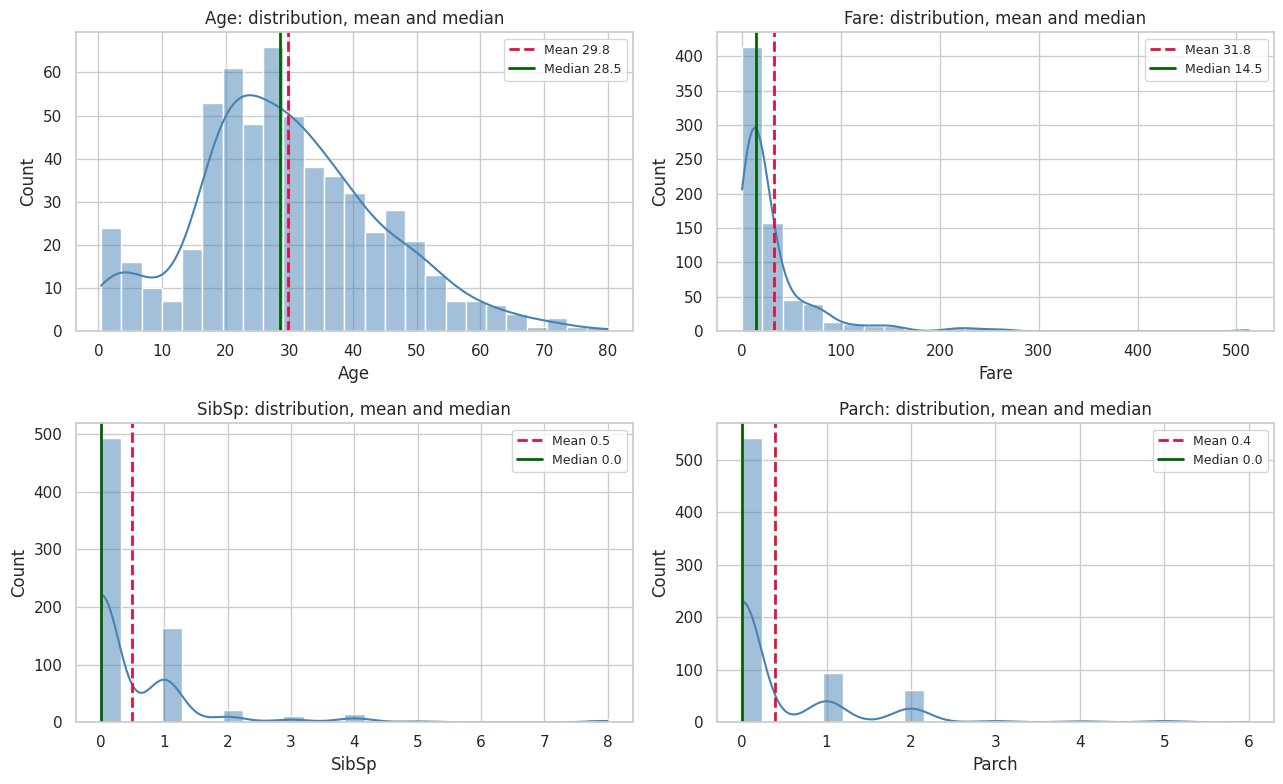

In [ ]:
NUMERIC_RAW = ["Age", "Fare", "SibSp", "Parch"]
summary = eda_df[NUMERIC_RAW].describe().T.rename(
    columns={"50%": "50% (median)", "25%": "Q1 (25%)", "75%": "Q3 (75%)"}
)
summary["median"] = eda_df[NUMERIC_RAW].median()
summary["IQR"] = summary["Q3 (75%)"] - summary["Q1 (25%)"]
summary["skewness"] = eda_df[NUMERIC_RAW].skew()
summary["missing_pct"] = 100 * eda_df[NUMERIC_RAW].isna().mean()
display(summary[["count", "mean", "median", "std", "min", "Q1 (25%)", "Q3 (75%)", "max", "IQR", "skewness", "missing_pct"]].round(2))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, NUMERIC_RAW):
    values = pd.to_numeric(eda_df[col], errors="coerce").dropna()
    sns.histplot(values, bins=25, kde=values.nunique() > 4, ax=ax, color="#4682B4")
    ax.axvline(values.mean(), color="crimson", ls="--", lw=2, label=f"Mean {values.mean():.1f}")
    ax.axvline(values.median(), color="darkgreen", lw=2, label=f"Median {values.median():.1f}")
    ax.set(title=f"{col}: distribution, mean and median", xlabel=col)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Categorical statistics

A mean is not meaningful for `Sex`, `Pclass`, or `Embarked`. Instead we inspect the **mode**, category frequencies, and number of levels. `Pclass` is represented as 1/2/3 but treated as a **category** rather than assuming linear distance between classes.

In [ ]:
CAT_RAW = ["Sex", "Pclass", "Embarked"]
cat_stats = []
for col in CAT_RAW:
    counts = eda_df[col].fillna("Missing").astype(str).value_counts(dropna=False)
    cat_stats.append({
        "feature": col,
        "mode": counts.index[0],
        "mode_count": int(counts.iloc[0]),
        "distinct_categories": int(counts.size),
        "missing_pct": 100 * eda_df[col].isna().mean(),
    })
    print(f"\n{col} (training rows):")
    display(pd.DataFrame({"count": counts, "pct": 100 * counts / len(eda_df)}).round(2))
display(pd.DataFrame(cat_stats).round(2))


Sex (training rows):


,count,pct
Sex,,
male,459,64.47
female,253,35.53



Pclass (training rows):


,count,pct
Pclass,,
3,391,54.92
1,171,24.02
2,150,21.07



Embarked (training rows):


,count,pct
Embarked,,
S,516,72.47
C,139,19.52
Q,55,7.72
Missing,2,0.28


,feature,mode,mode_count,distinct_categories,missing_pct
0,Sex,male,459,2,0.00
1,Pclass,3,391,3,0.00
2,Embarked,S,516,4,0.28


## 3 · Missing-data analysis and missingness patterns

Which features are incomplete? Does missingness differ by sex, passenger class, or survival label? This may indicate that missingness itself carries information.

The revised pipeline uses **median imputation** for numerical features and categorical missing-value handling. It also creates `AgeMissing` (1 if age was originally absent). Raw `Cabin` is excluded in the baseline because it is sparse. We do **not** assume that missingness is random.

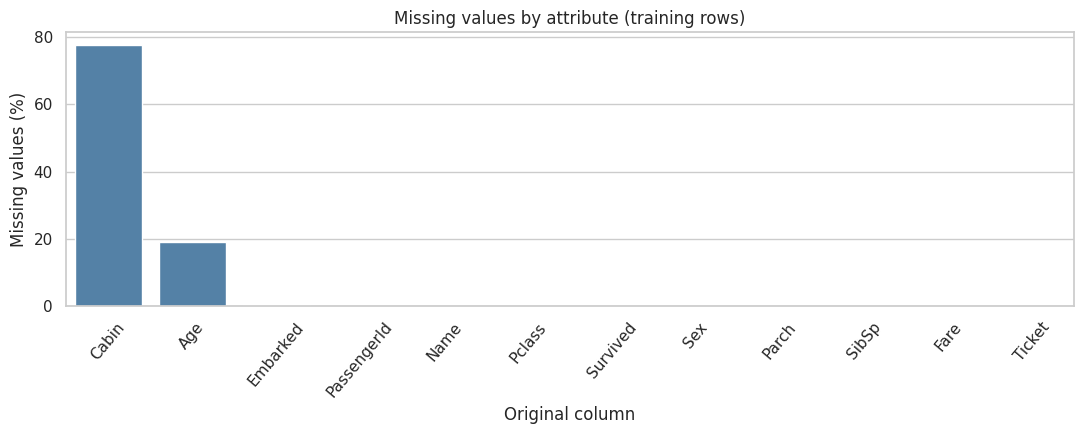

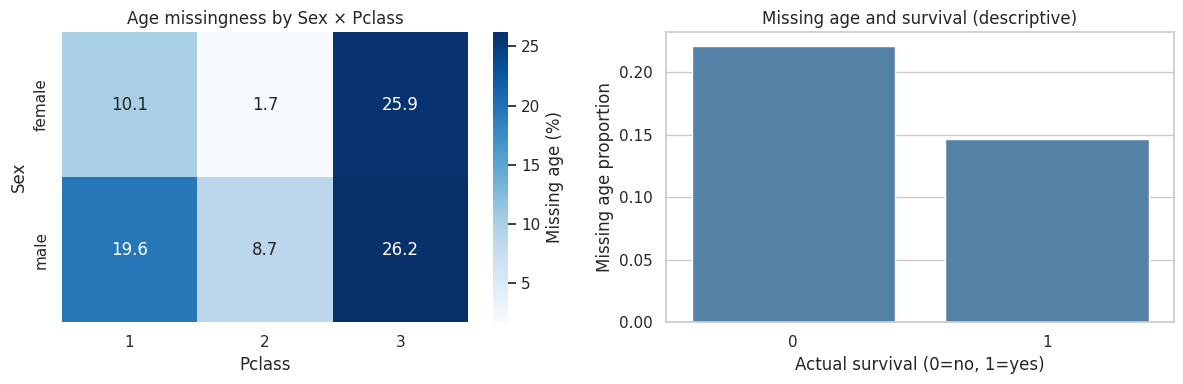

,passengers,survival_rate
AgeMissing,,
0,575,0.405
1,137,0.292


In [ ]:
missing_pct = (100 * eda_df.isna().mean()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=missing_pct.index, y=missing_pct.values, ax=ax, color="#4682B4")
ax.set(ylabel="Missing values (%)", xlabel="Original column", title="Missing values by attribute (training rows)")
ax.tick_params(axis="x", rotation=50)
plt.tight_layout()
plt.show()

# Plot age missingness across demographic groups.
missing_frame = eda_df.assign(AgeMissing=eda_df["Age"].isna().astype(int))
by_class_sex = missing_frame.pivot_table(
    index="Sex", columns="Pclass", values="AgeMissing", aggfunc="mean"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(by_class_sex * 100, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar_kws={"label": "Missing age (%)"})
axes[0].set_title("Age missingness by Sex × Pclass")
sns.barplot(data=missing_frame, x="Survived", y="AgeMissing", errorbar=None, ax=axes[1], color="#4682B4")
axes[1].set(xlabel="Actual survival (0=no, 1=yes)", ylabel="Missing age proportion", title="Missing age and survival (descriptive)")
plt.tight_layout()
plt.show()

age_missing_survival = missing_frame.groupby("AgeMissing")["Survived"].agg(["size", "mean"]).rename(columns={"size": "passengers", "mean": "survival_rate"})
display(age_missing_survival.round(3))

## 4 · Survival class balance and naive baseline

Is one label more common? If so, plain accuracy may be misleading.

We compute the majority-class accuracy as a reference, then plan to report **precision, recall, F1 and ROC AUC** as well as accuracy. Stratification preserves approximate label proportions in the development and validation partitions.

,passengers,percentage
Did not survive (0),439,61.66
Survived (1),273,38.34


Majority-class training accuracy: 61.66% (not a useful survival detector)


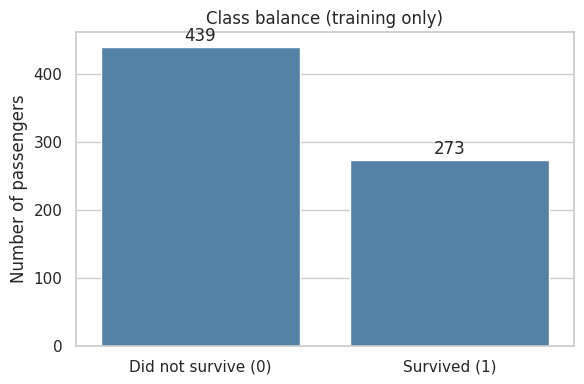

In [ ]:
counts = eda_df["Survived"].value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({"passengers": counts, "percentage": 100 * counts / len(eda_df)})
class_summary.index = ["Did not survive (0)", "Survived (1)"]
display(class_summary.round(2))
print(f"Majority-class training accuracy: {counts.max() / counts.sum():.2%} (not a useful survival detector)")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=class_summary.index, y=counts.values, ax=ax, color="#4682B4")
ax.set(ylabel="Number of passengers", xlabel="", title="Class balance (training only)")
for i, value in enumerate(counts.values):
    ax.text(i, value + max(counts) * 0.02, str(value), ha="center")
plt.tight_layout()
plt.show()

## 5 · Survival relationships: sex, class, embarkation

Which groups show different *observed* survival rates? Is the relationship between sex and survival different across passenger classes?

The mean of binary `Survived` is the survival rate. We report **group sample sizes** along with rates—very small groups can produce unstable estimates. These charts show *associations*, not causal effects.

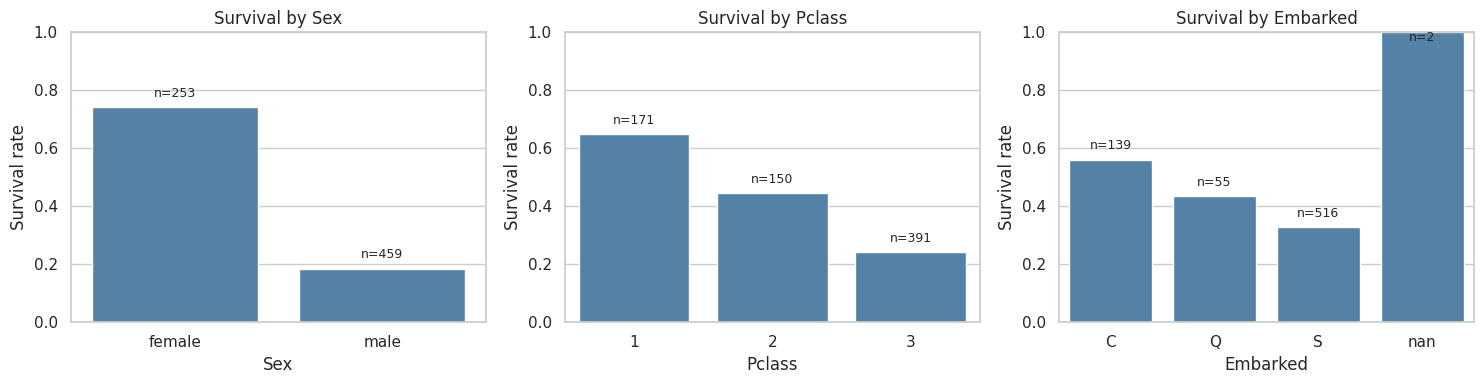

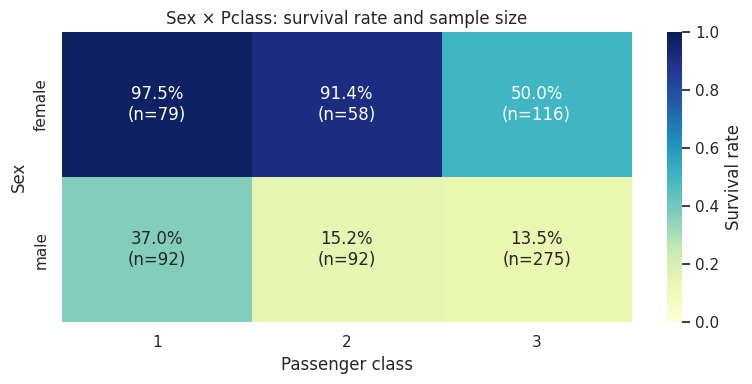

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["Sex", "Pclass", "Embarked"]):
    tab = eda_df.groupby(feature, dropna=False)["Survived"].agg(rate="mean", n="size").reset_index()
    tab[feature] = tab[feature].astype(str)
    sns.barplot(data=tab, x=feature, y="rate", ax=ax, color="#4682B4")
    ax.set(title=f"Survival by {feature}", ylabel="Survival rate", ylim=(0, 1))
    for i, row in tab.iterrows():
        ax.text(i, min(row["rate"] + 0.035, 0.97), f"n={row['n']}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

rate = eda_df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean")
group_n = eda_df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="size")
annotations = rate.copy().astype(object)
for r in rate.index:
    for c in rate.columns:
        annotations.loc[r, c] = f"{rate.loc[r,c]:.1%}\n(n={int(group_n.loc[r,c])})" if pd.notna(rate.loc[r,c]) else "n/a"
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(rate, annot=annotations.values, fmt="", cmap="YlGnBu", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Survival rate"})
ax.set(title="Sex × Pclass: survival rate and sample size", xlabel="Passenger class", ylabel="Sex")
plt.tight_layout()
plt.show()

## 6 · Age and fare by survival: distribution shape and transformation

Are survivor and non-survivor distributions different? Does fare show a strong right tail? Is `log(1 + Fare)` more compact and interpretable?

Comparing normalized densities is descriptive—not a test that the distributions have different population parameters. The model retains raw `Fare` **and** adds `LogFare`; we later check whether the derived features help in cross-validation.

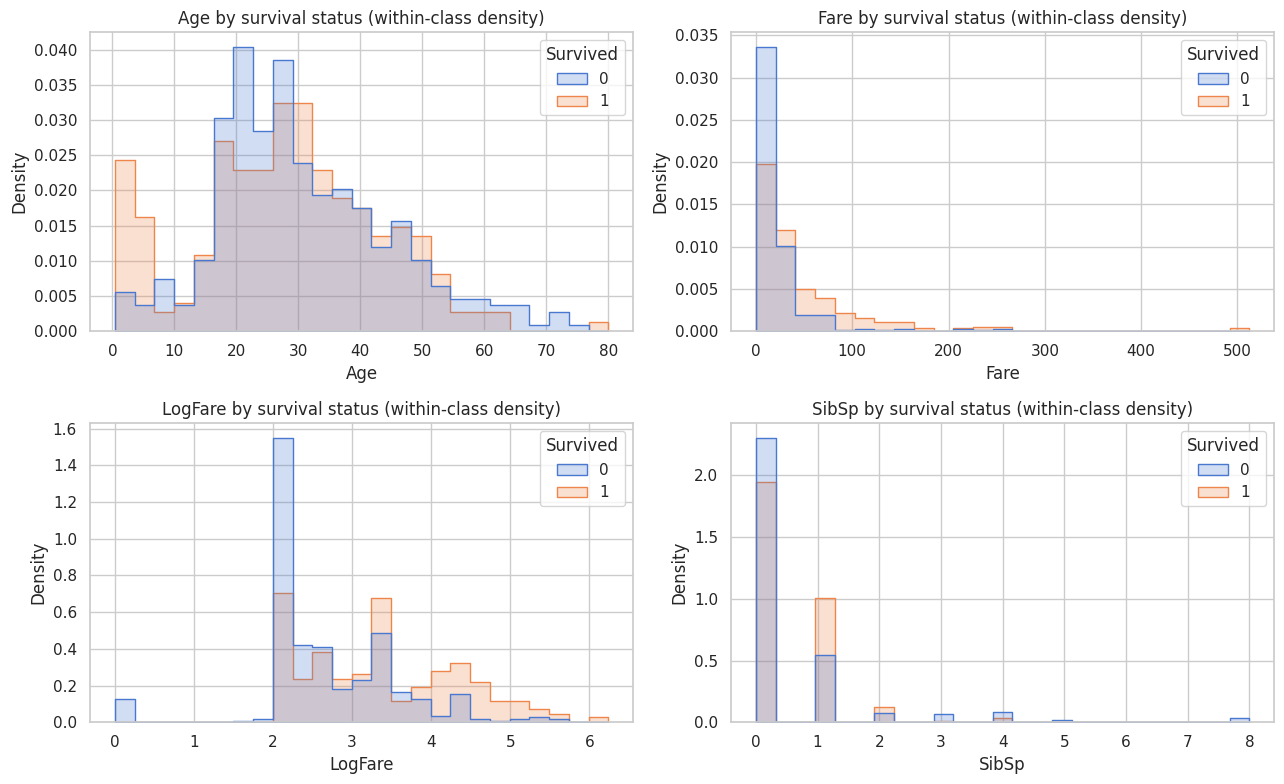

,feature,skewness,mean,median
0,Fare,4.646,31.820,14.454
1,LogFare,0.312,2.951,2.738


In [ ]:
plot_df = eda_df.copy()
plot_df["LogFare"] = np.log1p(pd.to_numeric(plot_df["Fare"], errors="coerce").clip(lower=0))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["Age", "Fare", "LogFare", "SibSp"]):
    sns.histplot(
        data=plot_df, x=col, hue="Survived", bins=25,
        stat="density", common_norm=False, element="step", ax=ax,
    )
    ax.set_title(f"{col} by survival status (within-class density)")
plt.tight_layout()
plt.show()

compare_skew = pd.DataFrame({
    "feature": ["Fare", "LogFare"],
    "skewness": [plot_df["Fare"].skew(), plot_df["LogFare"].skew()],
    "mean": [plot_df["Fare"].mean(), plot_df["LogFare"].mean()],
    "median": [plot_df["Fare"].median(), plot_df["LogFare"].median()],
})
display(compare_skew.round(3))

## 7 · Outlier analysis with the interquartile-range (IQR) rule

Which values are unusually far from the central distribution? Are they likely data errors or real high fares / large families?

For each numerical feature, the descriptive IQR fences are `Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR`. This is a **screening heuristic**, not proof of an invalid value. Particularly for heavily skewed `Fare`, many flagged observations may be genuine. **This notebook does not delete rows or clip outliers**: our training preprocessing also does not do this by default.

,feature,Q1,Q3,IQR,lower_fence,upper_fence,n_flagged,pct_of_nonmissing
0,Age,21.0,39.0,18.0,-6.00,66.00,6,1.04
1,Fare,7.9,31.0,23.1,-26.76,65.66,91,12.78
2,SibSp,0.0,1.0,1.0,-1.50,2.50,33,4.63
3,Parch,0.0,0.0,0.0,0.00,0.00,170,23.88


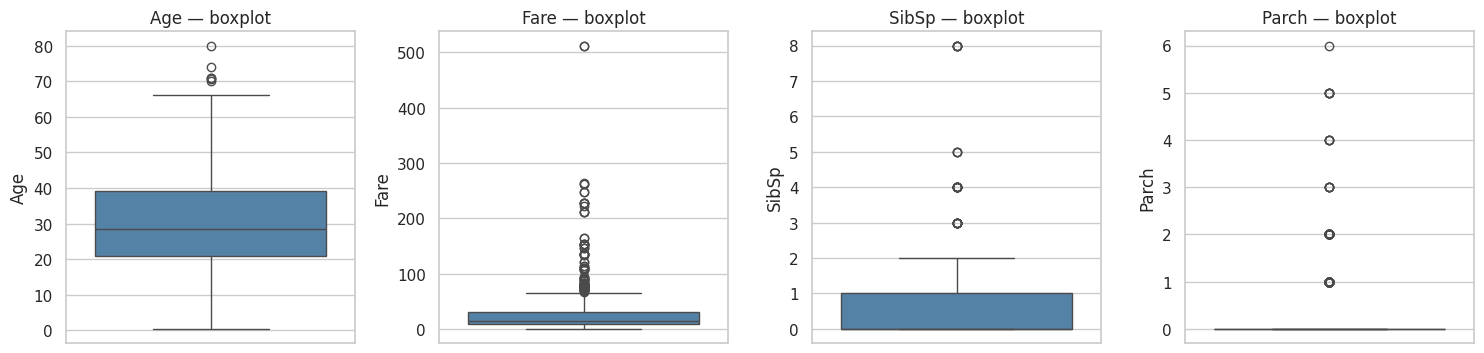

Note: flagged Fare values may be genuine; review instead of automatically dropping them.


In [ ]:
outlier_rows = []
for col in NUMERIC_RAW:
    series = pd.to_numeric(eda_df[col], errors="coerce").dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_flagged = int(((series < low) | (series > high)).sum())
    outlier_rows.append({
        "feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_fence": low, "upper_fence": high, "n_flagged": n_flagged,
        "pct_of_nonmissing": 100 * n_flagged / len(series),
    })
display(pd.DataFrame(outlier_rows).round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.7))
for ax, col in zip(axes, NUMERIC_RAW):
    sns.boxplot(y=eda_df[col], ax=ax, color="#4682B4")
    ax.set_title(f"{col} — boxplot")
plt.tight_layout()
plt.show()

print("Note: flagged Fare values may be genuine; review instead of automatically dropping them.")

## 8 · Feature engineering (mirrors updated training pipeline)


| Engineered feature | Definition | Hypothesis |
|---|---|---|
| `FamilySize` | `SibSp + Parch + 1` | Family context may matter |
| `IsAlone` | 1 when family size equals one | Traveling alone may matter |
| `FarePerPerson` | `Fare / FamilySize` | Approximate fare per family member |
| `Title` | Extract honorific from `Name` | Title can summarize age / social information |
| `LogFare` | `log(1 + max(Fare, 0))` | Compress fare outliers |
| `AgeMissing` | 1 when Age is missing | Missingness may carry signal |
| `SexPclass` | Combine normalized Sex and Pclass | Explicit interaction |

These are **hypotheses**, not proven improvements. `FarePerPerson` is not necessarily the true per-person ticket price.

In [ ]:
NUMERIC = ["Age", "SibSp", "Parch", "Fare", "LogFare", "FamilySize", "IsAlone", "FarePerPerson", "AgeMissing"]
CATEGORICAL = ["Pclass", "Sex", "Embarked", "Title", "SexPclass"]
COMMON_TITLES = {"Mr", "Mrs", "Miss", "Master"}
ENGINEERED = ["LogFare", "FamilySize", "IsAlone", "FarePerPerson", "AgeMissing", "Title", "SexPclass"]


def make_features(data: pd.DataFrame) -> pd.DataFrame:
    """Equivalent to the latest src/features.py supplied with the engineered train.py."""
    needed = {"Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"}
    absent = sorted(needed - set(data.columns))
    if absent:
        raise ValueError(f"Missing required passenger columns: {absent}")
    out = pd.DataFrame(index=data.index)
    for name in ("Age", "SibSp", "Parch", "Fare"):
        out[name] = pd.to_numeric(data[name], errors="coerce")
    out["AgeMissing"] = out["Age"].isna().astype(float)
    out["LogFare"] = np.log1p(out["Fare"].clip(lower=0))
    out["FamilySize"] = out["SibSp"] + out["Parch"] + 1
    out["IsAlone"] = (out["FamilySize"] == 1).astype(float)
    out.loc[out["FamilySize"].isna(), "IsAlone"] = np.nan
    out["FarePerPerson"] = out["Fare"] / out["FamilySize"].where(out["FamilySize"] > 0)
    pclass = pd.to_numeric(data["Pclass"], errors="coerce")
    out["Pclass"] = pclass.map({1: "1", 2: "2", 3: "3"}).fillna("Unknown")
    out["Sex"] = data["Sex"].astype("string").str.strip().str.lower().fillna("unknown")
    out["Embarked"] = data["Embarked"].astype("string").str.strip().str.upper().fillna("Unknown")
    out["SexPclass"] = out["Sex"].astype(str) + "_" + out["Pclass"].astype(str)
    if "Name" in data.columns:
        titles = data["Name"].astype("string").str.extract(r",\s*([A-Za-z]+)\.", expand=False).str.title()
        out["Title"] = titles.where(titles.isin(COMMON_TITLES), "Rare").fillna("Unknown")
    else:
        out["Title"] = "Unknown"
    return out[NUMERIC + CATEGORICAL]

engineered = make_features(eda_df)
print("Engineered training feature columns:", list(engineered.columns))
display(engineered.head(7))
print("Missing percentages after deterministic feature engineering (before imputation):")
display((100 * engineered.isna().mean()).sort_values(ascending=False).round(2).rename("Missing (%)").to_frame())

Engineered training feature columns: ['Age', 'SibSp', 'Parch', 'Fare', 'LogFare', 'FamilySize', 'IsAlone', 'FarePerPerson', 'AgeMissing', 'Pclass', 'Sex', 'Embarked', 'Title', 'SexPclass']


,Age,SibSp,Parch,Fare,LogFare,FamilySize,IsAlone,FarePerPerson,AgeMissing,Pclass,Sex,Embarked,Title,SexPclass
692,NaN,0,0,56.4958,4.051712,1,1.0,56.4958,1.0,3,male,S,Mr,male_3
481,NaN,0,0,0.0000,0.000000,1,1.0,0.0000,1.0,2,male,S,Mr,male_2
527,NaN,0,0,221.7792,5.406181,1,1.0,221.7792,1.0,1,male,S,Mr,male_1
855,18.0,0,1,9.3500,2.336987,2,0.0,4.6750,0.0,3,female,S,Mrs,female_3
801,31.0,1,1,26.2500,3.305054,3,0.0,8.7500,0.0,2,female,S,Mrs,female_2
652,21.0,0,0,8.4333,2.244246,1,1.0,8.4333,0.0,3,male,S,Mr,male_3
509,26.0,0,0,56.4958,4.051712,1,1.0,56.4958,0.0,3,male,S,Mr,male_3


Missing percentages after deterministic feature engineering (before imputation):


,Missing (%)
Age,19.24
SibSp,0.00
Parch,0.00
Fare,0.00
LogFare,0.00
FamilySize,0.00
IsAlone,0.00
FarePerPerson,0.00
AgeMissing,0.00
Pclass,0.00


## 9 · Analyze engineered features before accepting them

Do survival rates appear related to family size, passenger title, missing Age, or `SexPclass`? Are some engineered categories rare? Always show group counts; patterns from tiny groups should not drive the model design.

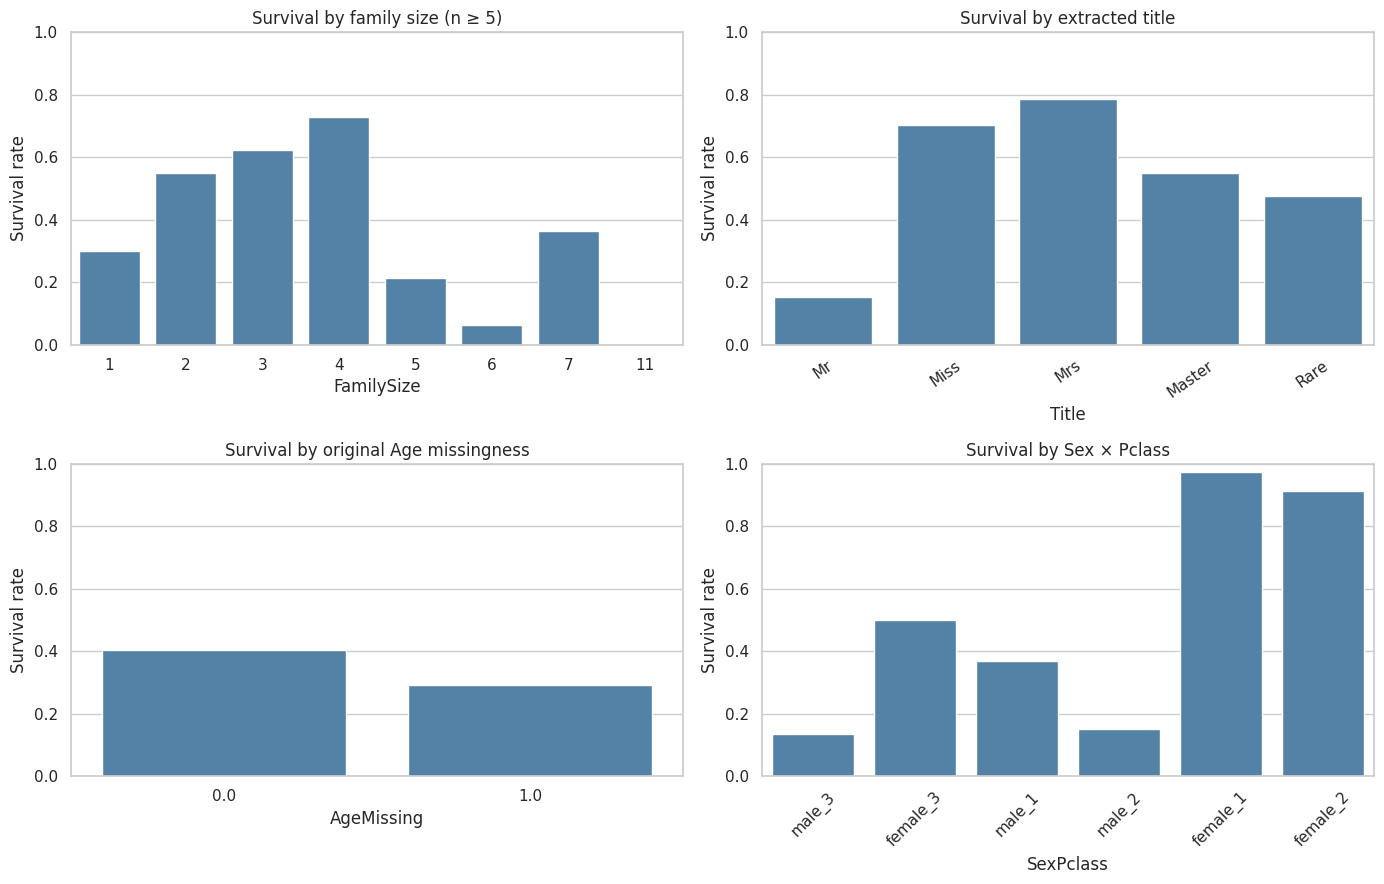

Survival by Title:


,rate,n
Title,,
Mr,0.153,412
Miss,0.702,141
Mrs,0.785,107
Master,0.548,31
Rare,0.476,21


Survival by SexPclass:


,rate,n
SexPclass,,
male_3,0.135,275
female_3,0.500,116
male_1,0.370,92
male_2,0.152,92
female_1,0.975,79
female_2,0.914,58


Survival by FamilySize:


,FamilySize,rate,n
0,1,0.300,434
1,2,0.550,129
2,3,0.623,77
3,4,0.727,22
4,5,0.214,14
5,6,0.062,16
6,7,0.364,11
7,8,0.000,4
8,11,0.000,5


In [ ]:
eng = engineered.join(eda_df["Survived"])
family_rates = eng.groupby("FamilySize")["Survived"].agg(rate="mean", n="size").reset_index()
family_plot = family_rates.loc[family_rates["n"] >= 5]

title_rates = eng.groupby("Title")["Survived"].agg(rate="mean", n="size").sort_values("n", ascending=False)
missing_rates = eng.groupby("AgeMissing")["Survived"].agg(rate="mean", n="size")
sexclass_rates = eng.groupby("SexPclass")["Survived"].agg(rate="mean", n="size").sort_values("n", ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.barplot(data=family_plot, x="FamilySize", y="rate", ax=axes[0,0], color="#4682B4")
axes[0,0].set(title="Survival by family size (n ≥ 5)", ylabel="Survival rate", ylim=(0, 1))
sns.barplot(data=title_rates.reset_index(), x="Title", y="rate", ax=axes[0,1], color="#4682B4")
axes[0,1].set(title="Survival by extracted title", ylabel="Survival rate", ylim=(0, 1))
axes[0,1].tick_params(axis="x", rotation=35)
sns.barplot(data=missing_rates.reset_index(), x="AgeMissing", y="rate", ax=axes[1,0], color="#4682B4")
axes[1,0].set(title="Survival by original Age missingness", ylabel="Survival rate", ylim=(0, 1))
sns.barplot(data=sexclass_rates.reset_index(), x="SexPclass", y="rate", ax=axes[1,1], color="#4682B4")
axes[1,1].set(title="Survival by Sex × Pclass", ylabel="Survival rate", ylim=(0, 1))
axes[1,1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Survival by Title:")
display(title_rates.round(3))
print("Survival by SexPclass:")
display(sexclass_rates.round(3))
print("Survival by FamilySize:")
display(family_rates.round(3))

## 10 · Correlation, redundancy and multicollinearity

Are any numerical features strongly correlated or mathematically redundant? Which linear associations are visible with survival?

`FamilySize` is derived from `SibSp` and `Parch`; `Fare` and `LogFare` carry overlapping information. Highly correlated inputs may be redundant, especially for logistic regression. Pearson correlation is only a *linear* description and does not capture every nonlinear relationship.

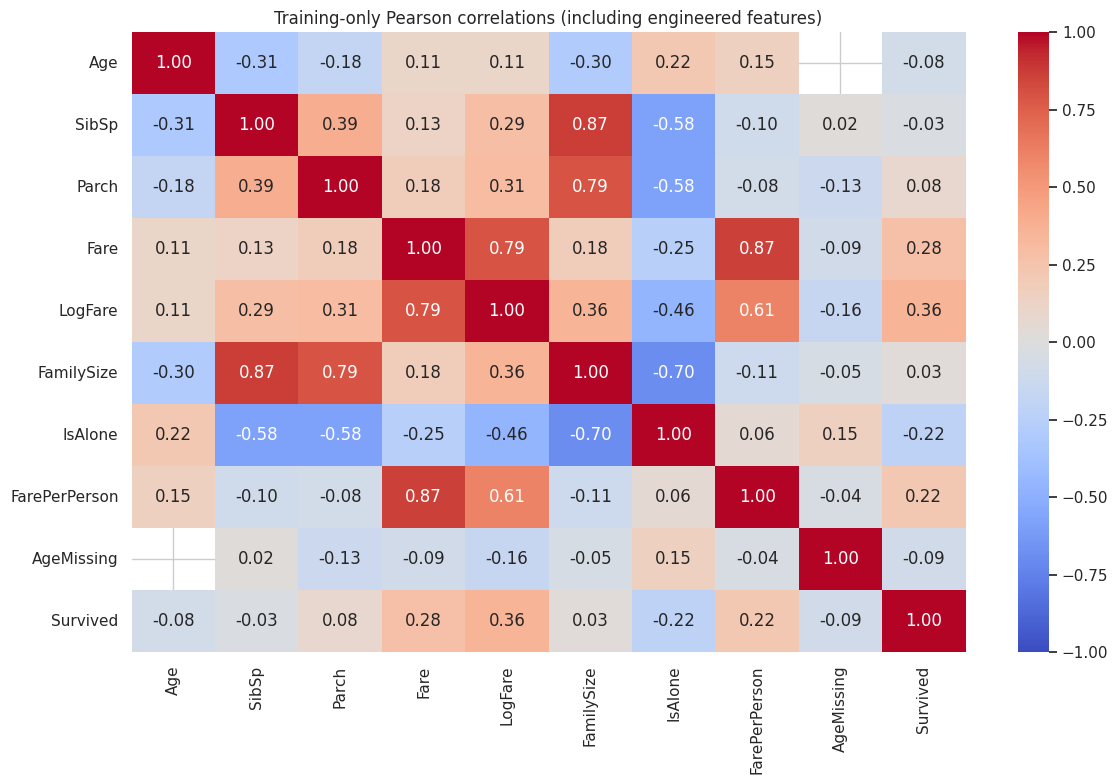

,feature_A,feature_B,Pearson_r,abs_r
10,SibSp,FamilySize,0.874,0.874
23,Fare,FarePerPerson,0.867,0.867
16,Parch,FamilySize,0.789,0.789
20,Fare,LogFare,0.789,0.789
29,FamilySize,IsAlone,-0.695,0.695
27,LogFare,FarePerPerson,0.606,0.606
17,Parch,IsAlone,-0.582,0.582
11,SibSp,IsAlone,-0.581,0.581
26,LogFare,IsAlone,-0.463,0.463
7,SibSp,Parch,0.392,0.392


In [ ]:
correlation_df = engineered[NUMERIC].copy()
correlation_df["Survived"] = eda_df["Survived"]
corr = correlation_df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax)
ax.set_title("Training-only Pearson correlations (including engineered features)")
plt.tight_layout()
plt.show()

pairs = []
features_only = corr.drop(index="Survived", columns="Survived")
for i, col_a in enumerate(features_only.columns):
    for col_b in features_only.columns[i+1:]:
        value = features_only.loc[col_a, col_b]
        if pd.notna(value):
            pairs.append((col_a, col_b, value, abs(value)))
strongest = pd.DataFrame(pairs, columns=["feature_A", "feature_B", "Pearson_r", "abs_r"])
if len(strongest):
    display(strongest.sort_values("abs_r", ascending=False).head(12).round(3))

## 11 · Actual preprocessing used before PyTorch training

The project uses a `ColumnTransformer` that learns its parameters on **training data only**:

1. Numerical: `SimpleImputer(strategy='median')` → `StandardScaler` (subtract training mean, divide by training standard deviation).
2. Categorical: `SimpleImputer(strategy='most_frequent')` → `OneHotEncoder(handle_unknown='ignore')`.
3. `Survived`, `PassengerId`, `Cabin`, and `Ticket` are **not** direct model inputs. `Name` only contributes its derived `Title`.
4. No automatic outlier deletion, no robust scaler, no class weighting, and no target-based feature transformation.

The checks below show the size and validity of the model input. We inspect validation **feature structure and finiteness only**, not held-out validation metrics or target associations.

In [ ]:
def build_preprocessor(numeric_cols=NUMERIC, categorical_cols=CATEGORICAL):
    numerical = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ])
    categoricals = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        [("numeric", numerical, list(numeric_cols)),
         ("categorical", categoricals, list(categorical_cols))],
        remainder="drop", sparse_threshold=0.0,
    )

preprocessor = build_preprocessor()
X_train = np.asarray(preprocessor.fit_transform(make_features(train_df)), dtype=np.float32)
X_val = np.asarray(preprocessor.transform(make_features(validation_df)), dtype=np.float32)
assert not (set(train_indices) & set(val_indices)), "Split overlap detected"
assert np.isfinite(X_train).all() and np.isfinite(X_val).all(), "NaN/Inf after preprocessing"
assert X_train.shape[1] == X_val.shape[1], "Feature dimension mismatch"

print("Training feature matrix:", X_train.shape)
print("Held-out feature matrix:", X_val.shape)
print("No overlapping rows; no NaN/Inf values after preprocessing.")
print("Class rate in development training:", f"{train_df['Survived'].mean():.2%}")
print("Validation features transformed without fitting any statistics to them.")
feature_names = list(preprocessor.get_feature_names_out())
print("Total transformed input dimension:", len(feature_names))
display(pd.DataFrame({"input_name": feature_names}).head(40))

numerical_pipe = preprocessor.named_transformers_["numeric"]
pre_scale_means = numerical_pipe.named_steps["scaler"].mean_
pre_scale_stds = numerical_pipe.named_steps["scaler"].scale_
imputation_medians = numerical_pipe.named_steps["imputer"].statistics_
parameters = pd.DataFrame({
    "numeric_feature": NUMERIC,
    "training_imputation_median": imputation_medians,
    "training_mean_after_imputation": pre_scale_means,
    "training_scaler_std": pre_scale_stds,
})
print("Fitted preprocessing parameters (training data only):")
display(parameters.round(3))

Training feature matrix: (712, 29)
Held-out feature matrix: (179, 29)
No overlapping rows; no NaN/Inf values after preprocessing.
Class rate in development training: 38.34%
Validation features transformed without fitting any statistics to them.
Total transformed input dimension: 29


,input_name
0,numeric__Age
1,numeric__SibSp
2,numeric__Parch
3,numeric__Fare
4,numeric__LogFare
5,numeric__FamilySize
6,numeric__IsAlone
7,numeric__FarePerPerson
8,numeric__AgeMissing
9,categorical__Pclass_1


Fitted preprocessing parameters (training data only):


,numeric_feature,training_imputation_median,training_mean_after_imputation,training_scaler_std
0,Age,28.500,29.556,13.016
1,SibSp,0.000,0.493,1.060
2,Parch,0.000,0.390,0.838
3,Fare,14.454,31.820,48.025
4,LogFare,2.738,2.951,0.979
5,FamilySize,1.000,1.883,1.588
6,IsAlone,1.000,0.610,0.488
7,FarePerPerson,8.446,20.397,37.689
8,AgeMissing,0.000,0.192,0.394


## 12 · Feature-ablation experiment (training partition only)

Does engineering features actually improve prediction—or just add complexity?

We run **5-fold stratified cross-validation on the 80% training partition only**. Each fold refits the feature preprocessing from scratch, so the fold's validation rows do not affect medians, means, or category vocabularies. This uses **logistic regression as a fast diagnostic model**, not MLP; feature usefulness may differ by model.

Variants: original features; original + family; original + title; original + log fare; original + sex/class; all engineered features. We report accuracy, F1, and ROC AUC as means and fold-to-fold standard deviations. **Do not use the reserved 20% holdout to select features or epochs.**

,configuration,accuracy_mean,accuracy_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,A · Original seven,0.8020,0.0158,0.7301,0.0243,0.8532,0.0242
1,B · + Family features,0.7978,0.0150,0.7248,0.0247,0.8561,0.0241
2,C · + Title,0.8202,0.0235,0.7605,0.0276,0.8684,0.0217
3,D · + LogFare,0.7865,0.0235,0.7129,0.0328,0.8581,0.0278
4,E · + SexPclass,0.8090,0.0079,0.7244,0.0137,0.8607,0.0177
5,F · All engineered,0.8259,0.0286,0.7591,0.0356,0.8718,0.0229


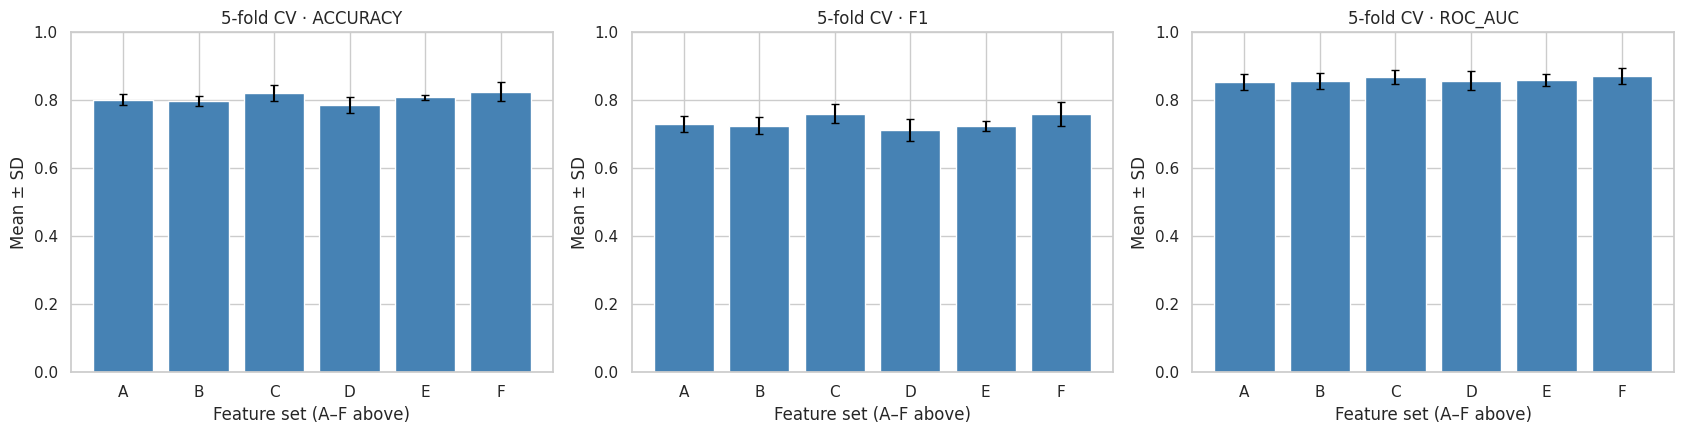

Highest mean CV ROC AUC in this exploration: F · All engineered (0.872).
Caution: small differences can be sampling noise; no model has been retrained or selected by this notebook.


In [ ]:
BASE_NUM = ["Age", "SibSp", "Parch", "Fare"]
BASE_CAT = ["Pclass", "Sex", "Embarked"]
ABLATIONS = {
    "A · Original seven": (BASE_NUM, BASE_CAT),
    "B · + Family features": (BASE_NUM + ["FamilySize", "IsAlone", "FarePerPerson"], BASE_CAT),
    "C · + Title": (BASE_NUM, BASE_CAT + ["Title"]),
    "D · + LogFare": (BASE_NUM + ["LogFare"], BASE_CAT),
    "E · + SexPclass": (BASE_NUM, BASE_CAT + ["SexPclass"]),
    "F · All engineered": (NUMERIC, CATEGORICAL),
}

# Input columns, target labels stay separate. The pipeline's preprocessing is refitted within each fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []
for experiment, (numerical_features, categorical_features) in ABLATIONS.items():
    estimator = Pipeline([
        ("engineering", FunctionTransformer(make_features, validate=False)),
        ("preprocess", build_preprocessor(numerical_features, categorical_features)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    scores = cross_validate(
        estimator, train_df, train_df["Survived"], cv=cv,
        scoring={"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"},
        error_score="raise", n_jobs=1,
    )
    record = {"configuration": experiment}
    for metric in ["accuracy", "f1", "roc_auc"]:
        vals = scores[f"test_{metric}"]
        record[f"{metric}_mean"] = vals.mean()
        record[f"{metric}_std"] = vals.std(ddof=1)
    cv_results.append(record)
cv_table = pd.DataFrame(cv_results)
display(cv_table.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["accuracy", "f1", "roc_auc"]):
    x = np.arange(len(cv_table))
    ax.bar(x, cv_table[f"{metric}_mean"], color="#4682B4")
    ax.errorbar(x, cv_table[f"{metric}_mean"], yerr=cv_table[f"{metric}_std"], fmt="none", ecolor="black", capsize=3)
    ax.set_xticks(x)
    ax.set_xticklabels(list("ABCDEF"))
    ax.set(title=f"5-fold CV · {metric.upper()}", xlabel="Feature set (A–F above)", ylabel="Mean ± SD", ylim=(0, 1))
plt.tight_layout()
plt.show()

best = cv_table.loc[cv_table["roc_auc_mean"].idxmax()]
print(f"Highest mean CV ROC AUC in this exploration: {best['configuration']} ({best['roc_auc_mean']:.3f}).")
print("Caution: small differences can be sampling noise; no model has been retrained or selected by this notebook.")

## 13 · Evidence-based preprocessing decisions and limitations

**Summary of decisions supported by the checks above**

| Check / observation | Preprocessing or modeling decision | Caveat |
|---|---|---|
| Missing numerical values (especially Age) | Median imputation; add `AgeMissing` | Median is fit **on training folds only** |
| High fare skewness or outliers | Add `LogFare` and standardize | Raw Fare is also retained; ablation determines value |
| Categorical variables | One-hot encoding with unseen-category tolerance | Rare categories may be unstable |
| Strong `Sex × Pclass` association | Test explicit `SexPclass` interaction | Observational correlation is **not** causality |
| Family variables | Test `FamilySize`, `IsAlone`, `FarePerPerson` | Engineered variables can be redundant |
| Highly incomplete `Cabin` | Exclude raw Cabin from baseline | An advanced model could extract deck instead |
| Survival class imbalance | Stratified split; accuracy, F1, precision/recall, AUC | We are **not** using a class-weighted loss |
| Moderate sample size | Small MLP and logistic-regression baseline | Train/validation results can vary with split |
| Potential outliers | Inspect IQR and boxplots | Do **not** delete valid records blindly |

**Important safeguards**

- The **EDA notebook is exploratory** and does not train or save your PyTorch model. `train.py` implements the production model.
- The reserved 20% validation data is **not used** in the feature-ablation analysis above. Repeated comparison using one holdout can bias a final performance estimate.
- This notebook's feature code should remain consistent with the actual `src/features.py`. Any change in input features requires retraining and re-saving `model.pt` and `preprocessor.joblib`.
- The ablation compares feature sets for **logistic regression**. It does not prove the same ranking for an MLP.
- The assignment specifies Titanic **`train.csv` only**; do not use Kaggle `test.csv` or `gender_submission.csv` in evaluation.

**Next steps:** use training-only cross-validation to choose model complexity, test the selected PyTorch configuration, and report the final reserved holdout results in Streamlit. Explain both positive and negative findings rather than claiming every engineered feature improves performance.

### Auto-generated statistics

This text derives from **the actual training partition** and is safe to adapt into the README / EDA conclusions. It is not a causal claim or a held-out test result.

In [ ]:
missing_age = 100 * eda_df["Age"].isna().mean()
missing_cabin = 100 * eda_df["Cabin"].isna().mean() if "Cabin" in eda_df else float("nan")
fare_skew = eda_df["Fare"].skew()
observed_survival = 100 * eda_df["Survived"].mean()
most_informative_cv = str(best["configuration"])
text = (
    f"**Training-partition findings:** Among {len(eda_df)} passengers, "
    f"the observed survival rate was {observed_survival:.1f}%. "
    f"Age had {missing_age:.1f}% missing values; "
    + (f"Cabin had {missing_cabin:.1f}% missing values. " if np.isfinite(missing_cabin) else "")
    + f"Fare skewness was {fare_skew:.2f}, motivating inspection of a log-transformed fare. "
    f"We use median imputation, train-fitted scaling, one-hot encoding, and engineered passenger features. "
    f"A 5-fold logistic-regression feature-ablation exercise produced its highest mean ROC AUC for "
    f"{most_informative_cv}, but this exploratory result does not establish which features optimize the PyTorch model."
)
display(Markdown(text))

**Training-partition findings:** Among 712 passengers, the observed survival rate was 38.3%. Age had 19.2% missing values; Cabin had 77.5% missing values. Fare skewness was 4.65, motivating inspection of a log-transformed fare. We use median imputation, train-fitted scaling, one-hot encoding, and engineered passenger features. A 5-fold logistic-regression feature-ablation exercise produced its highest mean ROC AUC for F · All engineered, but this exploratory result does not establish which features optimize the PyTorch model.

---
**Reproducibility:** `RANDOM_STATE = 42`; 20% held-out validation, 80% EDA/development; 5-fold stratified CV for feature ablation; only local `train.csv`.